# 03 — Signal Quality Assessment

## Objective

The aim of this notebook is to assess the quality of the selected SEEG recording and identify channels with potentially unusual signal characteristics.

We will:

- Calculate descriptive statistics for all 31 channels.
- Compare signal characteristics across channels and between the pre- and post-stimulation epochs.
- Identify channels that may require further inspection.
- Visually inspect selected channels.

This is an exploratory quality assessment. Statistical deviations do not automatically indicate bad channels or abnormal brain activity.

## Recording

This notebook uses the same recording explored in Notebook 02:

- Participant: `sub-01`
- Session: `ses-01`
- Recording duration: 32 seconds
- Number of channels: 31
- Sampling frequency: 4096 Hz
- Pre-stimulation epoch: 5 seconds
- Post-stimulation epoch: 5 seconds

In [1]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Define the path to the raw dataset
RAW_DATA_DIR = Path("../data/raw")

recording_path = (
    RAW_DATA_DIR / "sub-01" / "ses-01" / "ieeg"
    / "sub-01_ses-01_task-dcs_ieeg.vhdr"
)

# Load the recording
raw = mne.io.read_raw_brainvision(
    recording_path,
    preload=True,
    verbose=False
)

print(raw)

<RawBrainVision | sub-01_ses-01_task-dcs_ieeg.eeg, 31 x 131072 (32.0 s), ~31.0 MiB, data loaded>


In [2]:
# Basic recording information
sfreq = raw.info["sfreq"]
n_channels = len(raw.ch_names)
n_samples = raw.n_times
duration = n_samples / sfreq

print(f"Sampling frequency: {sfreq} Hz")
print(f"Number of channels: {n_channels}")
print(f"Number of samples: {n_samples}")
print(f"Recording duration: {duration} seconds")
print(f"Channel names: {raw.ch_names}")

Sampling frequency: 4096.0 Hz
Number of channels: 31
Number of samples: 131072
Recording duration: 32.0 seconds
Channel names: ["B'02-B'03", "B'03-B'04", "B'11-B'12", "A'01-A'02", "A'02-A'03", "A'03-A'04", "A'13-A'14", "I'01-I'02", "I'04-I'05", "I'07-I'08", "I'13-I'14", "H'01-H'02", "H'11-H'12", "O'01-O'02", "O'11-O'12", "M'14-M'15", 'B01-B02', 'B05-B06', 'B11-B12', 'A01-A02', 'A02-A03', 'A03-A04', 'A11-A12', 'I01-I02', 'I02-I03', 'I03-I04', 'I12-I13', 'H13-H14', 'O01-O02', 'O11-O12', 'M14-M15']


In [6]:
# Extract the signal data
data = raw.get_data()

print("Data shape:", data.shape)

Data shape: (31, 131072)


In [4]:
# Calculate descriptive statistics for each channel

channel_stats = pd.DataFrame({
    "Channel": raw.ch_names,
    "Mean (µV)": np.mean(data, axis=1) * 1e6,
    "Median (µV)": np.median(data, axis=1) * 1e6,
    "Standard deviation (µV)": np.std(data, axis=1) * 1e6,
    "Minimum (µV)": np.min(data, axis=1) * 1e6,
    "Maximum (µV)": np.max(data, axis=1) * 1e6
})

channel_stats

,Channel,Mean (µV),Median (µV),Standard deviation (µV),Minimum (µV),Maximum (µV)
0,B'02-B'03,0.679469,7.632889,131.150162,-774.684631,764.620850
1,B'03-B'04,17.856047,24.570131,114.367980,-427.852600,374.453888
2,B'11-B'12,-1.099683,-0.454263,80.322208,-887.599548,2028.657959
3,A'01-A'02,-3.153047,-4.879309,117.561677,-667.567993,614.779602
4,A'02-A'03,19.408421,-14.950102,192.721783,-1009.059448,861.056274
5,A'03-A'04,-20.019657,1.681965,285.054725,-1361.384644,1598.360352
6,A'13-A'14,172.791821,375.064240,706.631493,-1659.693726,1282.198486
7,I'01-I'02,7.047908,10.379469,76.069927,-1323.848022,1364.138184
8,I'04-I'05,4.345108,6.259599,183.671024,-988.307495,1068.728271
9,I'07-I'08,-2.903441,5.954423,70.890422,-367.427856,276.797729


In [7]:
# Sort channels from highest to lowest standard deviation

channel_stats_sorted = channel_stats.sort_values(
    by="Standard deviation (µV)",
    ascending=False
)

channel_stats_sorted

,Channel,Mean (µV),Median (µV),Standard deviation (µV),Minimum (µV),Maximum (µV)
6,A'13-A'14,172.791821,375.064240,706.631493,-1659.693726,1282.198486
5,A'03-A'04,-20.019657,1.681965,285.054725,-1361.384644,1598.360352
4,A'02-A'03,19.408421,-14.950102,192.721783,-1009.059448,861.056274
8,I'04-I'05,4.345108,6.259599,183.671024,-988.307495,1068.728271
28,O01-O02,25.341770,-11.135407,133.409804,-384.365082,411.532715
0,B'02-B'03,0.679469,7.632889,131.150162,-774.684631,764.620850
3,A'01-A'02,-3.153047,-4.879309,117.561677,-667.567993,614.779602
1,B'03-B'04,17.856047,24.570131,114.367980,-427.852600,374.453888
10,I'13-I'14,-10.038383,3.818194,90.401048,-410.305023,187.991638
2,B'11-B'12,-1.099683,-0.454263,80.322208,-887.599548,2028.657959


## Initial descriptive statistics

We extracted the signal data from the selected SEEG recording and calculated descriptive statistics for each of the 31 channels across the full 32-second recording.

For each channel, we calculated:

- **Mean:** the average voltage.
- **Median:** the middle voltage value.
- **Standard deviation:** a measure of voltage variability around the mean.
- **Minimum and maximum:** the lowest and highest recorded voltage values.

The signal is internally represented in volts (V), so we converted the results to microvolts (µV) for easier interpretation.

We then sorted the channels by standard deviation, from highest to lowest, to identify those with the greatest signal variability.

The three channels with the highest standard deviations were:

| Channel | Standard deviation (µV) |
|---|---:|
| A'13-A'14 | 706.63 |
| A'03-A'04 | 285.05 |
| A'02-A'03 | 192.72 |

A'13-A'14 showed substantially greater variability than the other channels in this initial overview.

**Interpretation and limitations**

These statistics describe the entire recording, including the period containing the high-frequency electrical stimulation artefact. Consequently, the observed variability may partly reflect the artefact rather than the underlying brain signal.

Higher variability alone does not establish that a channel is faulty or that its neural activity is abnormal. These results are therefore treated as an initial screening step, not as a basis for excluding channels.

In the next step, we will examine the descriptive statistics separately for the annotated pre-stimulation and post-stimulation epochs.

In [8]:
# Define the annotated epoch timings
pre_start = 6.99823
post_start = 19.05
epoch_duration = 5.0

# Extract the pre- and post-stimulation data
pre_data = raw.get_data(
    start=int(pre_start * sfreq),
    stop=int((pre_start + epoch_duration) * sfreq)
)

post_data = raw.get_data(
    start=int(post_start * sfreq),
    stop=int((post_start + epoch_duration) * sfreq)
)

print("Pre-stimulation shape:", pre_data.shape)
print("Post-stimulation shape:", post_data.shape)

Pre-stimulation shape: (31, 20480)
Post-stimulation shape: (31, 20480)


In [9]:
# Calculate standard deviation for each channel in both epochs

epoch_stats = pd.DataFrame({
    "Channel": raw.ch_names,
    "Pre-stimulation SD (µV)": np.std(pre_data, axis=1) * 1e6,
    "Post-stimulation SD (µV)": np.std(post_data, axis=1) * 1e6
})

epoch_stats

,Channel,Pre-stimulation SD (µV),Post-stimulation SD (µV)
0,B'02-B'03,29.102241,69.908491
1,B'03-B'04,89.979798,87.248805
2,B'11-B'12,14.857752,47.755304
3,A'01-A'02,52.179139,27.762777
4,A'02-A'03,30.553408,119.742288
5,A'03-A'04,26.655860,127.004002
6,A'13-A'14,208.684787,397.506673
7,I'01-I'02,11.440434,13.223163
8,I'04-I'05,35.050891,27.612061
9,I'07-I'08,36.918354,65.526850


## Descriptive statistics across annotated epochs

We calculated the standard deviation separately for each channel during the five-second pre-stimulation and post-stimulation epochs.

The channels with the highest variability were:

| Rank | Pre-stimulation | SD (µV) | Post-stimulation | SD (µV) |
|---|---|---:|---|---:|
| 1 | A'13-A'14 | 208.68 | A'13-A'14 | 397.51 |
| 2 | B'03-B'04 | 89.98 | A'03-A'04 | 127.00 |
| 3 | O01-O02 | 70.42 | A'02-A'03 | 119.74 |

A'13-A'14 showed the highest standard deviation in both epochs. Several channels also showed greater variability in the post-stimulation epoch, although this pattern was not consistent across all channels.

These results identify channels that may warrant further visual inspection. However, differences in standard deviation alone cannot establish whether a channel is faulty or whether the observed signal differences reflect physiological activity, residual artefacts or other recording factors.

The results are descriptive and refer only to the selected recording and annotated epochs.

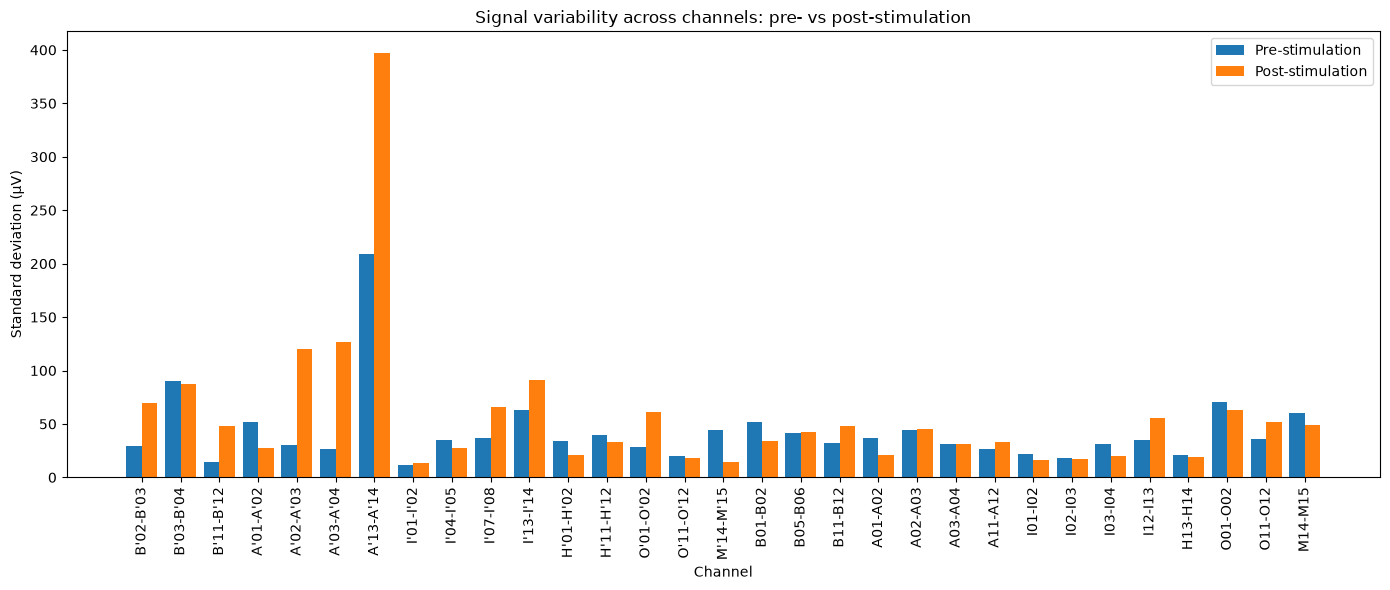

In [10]:
# Plot standard deviation across channels in both epochs

x = np.arange(len(epoch_stats))
width = 0.4

plt.figure(figsize=(14, 6))

plt.bar(
    x - width / 2,
    epoch_stats["Pre-stimulation SD (µV)"],
    width,
    label="Pre-stimulation"
)

plt.bar(
    x + width / 2,
    epoch_stats["Post-stimulation SD (µV)"],
    width,
    label="Post-stimulation"
)

plt.xticks(x, epoch_stats["Channel"], rotation=90)
plt.xlabel("Channel")
plt.ylabel("Standard deviation (µV)")
plt.title("Signal variability across channels: pre- vs post-stimulation")
plt.legend()
plt.tight_layout()
plt.show()

## Comparison of signal variability across epochs

The comparison of standard deviation across the 31 channels revealed three channels with particularly pronounced increases in variability in the post-stimulation epoch:

| Channel | Pre SD (µV) | Post SD (µV) | Post/pre ratio |
|---|---:|---:|---:|
| A'02-A'03 | 30.55 | 119.74 | 3.92 |
| A'03-A'04 | 26.66 | 127.00 | 4.76 |
| A'13-A'14 | 208.68 | 397.51 | 1.91 |

A'02-A'03 and A'03-A'04 showed the largest relative increases, while A'13-A'14 had the highest absolute variability in both epochs.

These channels were selected for further visual inspection.

There is no universal threshold that defines a normal difference in standard deviation between SEEG channels or epochs. Therefore, the remaining differences are described as less pronounced rather than assumed to be normal.

These observations are exploratory and do not establish the cause of the increased variability.

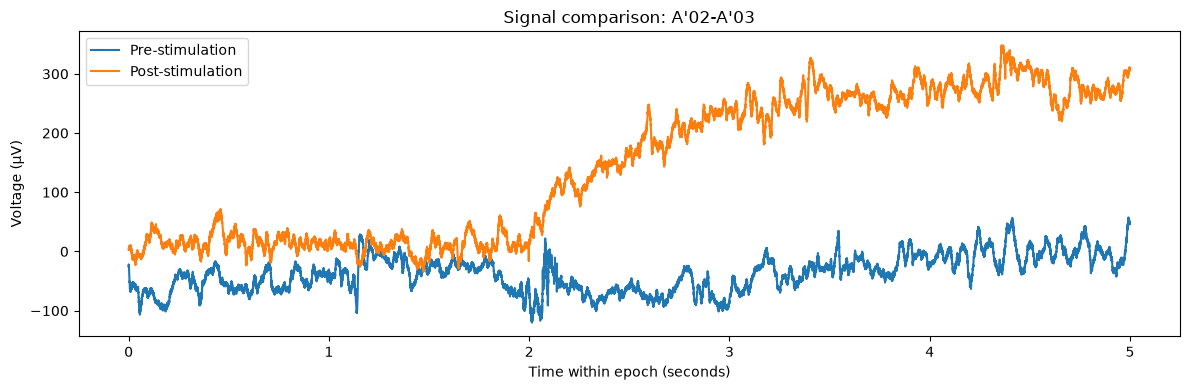

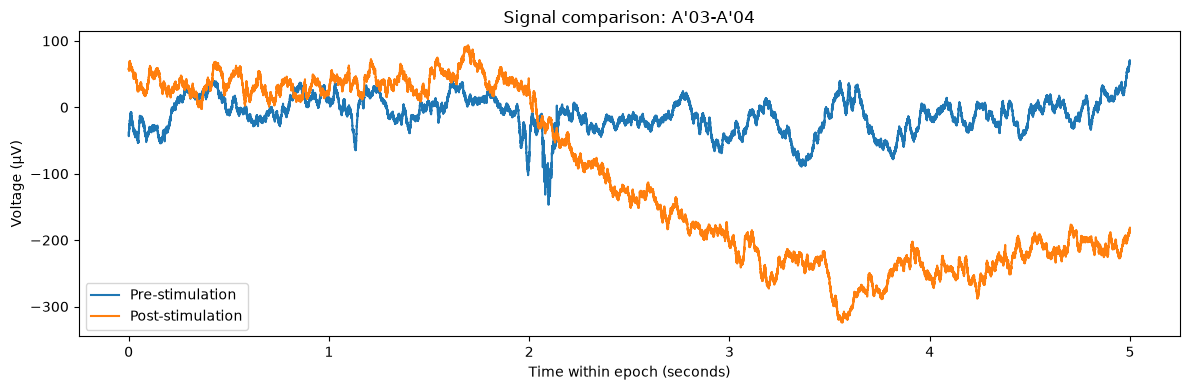

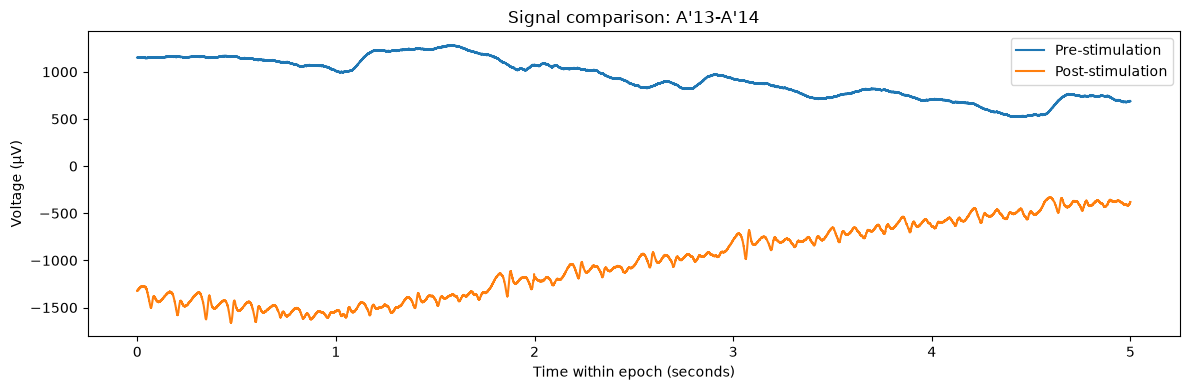

In [11]:
# Channels selected for visual inspection
selected_channels = ["A'02-A'03", "A'03-A'04", "A'13-A'14"]

# Create time axes for both epochs
pre_time = np.arange(pre_data.shape[1]) / sfreq
post_time = np.arange(post_data.shape[1]) / sfreq

# Plot each selected channel
for channel in selected_channels:

    channel_idx = raw.ch_names.index(channel)

    plt.figure(figsize=(12, 4))

    plt.plot(
        pre_time,
        pre_data[channel_idx] * 1e6,
        label="Pre-stimulation"
    )

    plt.plot(
        post_time,
        post_data[channel_idx] * 1e6,
        label="Post-stimulation"
    )

    plt.xlabel("Time within epoch (seconds)")
    plt.ylabel("Voltage (µV)")
    plt.title(f"Signal comparison: {channel}")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [12]:
# Compare mean voltage across the selected channels

selected_stats = pd.DataFrame({
    "Channel": selected_channels,
    "Pre mean (µV)": [
        np.mean(pre_data[raw.ch_names.index(ch)]) * 1e6
        for ch in selected_channels
    ],
    "Post mean (µV)": [
        np.mean(post_data[raw.ch_names.index(ch)]) * 1e6
        for ch in selected_channels
    ]
})

selected_stats["Mean difference (µV)"] = (
    selected_stats["Post mean (µV)"]
    - selected_stats["Pre mean (µV)"]
)

selected_stats

,Channel,Pre mean (µV),Post mean (µV),Mean difference (µV)
0,A'02-A'03,-37.129874,144.920577,182.050451
1,A'03-A'04,-11.748634,-102.756124,-91.007489
2,A'13-A'14,936.639401,-1023.416898,-1960.056299


## Visual inspection of selected channels

The three channels with the most pronounced differences in standard deviation were visually inspected.

- **A'02-A'03 and A'03-A'04:** Both epochs show frequent voltage fluctuations, including numerous small peaks and some larger excursions. The post-stimulation traces appear visually thicker, consistent with their higher standard deviations.
- **A'13-A'14:** The pre- and post-stimulation traces show a visibly different pattern, and they do not intersect in the plotted epochs. This observation alone does not indicate poor signal quality and requires further examination.

The visual inspection is consistent with the descriptive statistics, which identified increased variability in the post-stimulation epochs of all three channels.

These observations describe the recorded voltage signals and do not establish the physiological or technical causes of the differences.

In [13]:
# Inspect minimum and maximum voltage in both epochs

channel = "A'13-A'14"
channel_idx = raw.ch_names.index(channel)

range_stats = pd.DataFrame({
    "Epoch": ["Pre-stimulation", "Post-stimulation"],
    "Minimum (µV)": [
        np.min(pre_data[channel_idx]) * 1e6,
        np.min(post_data[channel_idx]) * 1e6
    ],
    "Maximum (µV)": [
        np.max(pre_data[channel_idx]) * 1e6,
        np.max(post_data[channel_idx]) * 1e6
    ]
})

range_stats

,Epoch,Minimum (µV),Maximum (µV)
0,Pre-stimulation,521.090759,1282.198486
1,Post-stimulation,-1659.693726,-331.722321


## Conclusions and limitations

### Main observations

The signal-quality assessment identified several channels with potentially unusual signal characteristics.

- A'13-A'14 showed the highest standard deviation in both annotated epochs and a substantial increase in variability in the post-stimulation epoch.
- A'02-A'03 and A'03-A'04 showed particularly pronounced relative increases in post-stimulation variability.
- Visual inspection supported these observations, revealing more pronounced voltage fluctuations in the post-stimulation signals.
- A'13-A'14 also showed a substantial difference in mean voltage between epochs. Its pre-stimulation values were entirely positive, whereas its post-stimulation values were entirely negative.

### Interpretation

These observations identify channels that warrant further investigation during subsequent signal analysis.

In particular, the large voltage offset and increased variability observed in A'13-A'14 should be considered when interpreting its spectral characteristics.

However, the observed differences cannot be attributed to a specific physiological or technical cause based on this assessment alone.

### Limitations

- The analysis concerns one participant, one session and one recording.
- Only two annotated five-second epochs were compared.
- Descriptive statistics cannot independently establish channel quality or identify the cause of signal differences.
- No filtering or artefact-removal procedures were applied.
- Channels were not automatically excluded based on statistical deviations.

### Next steps

The identified channels will receive particular attention during spectral analysis. All channels will initially be retained to avoid excluding potentially informative signals without sufficient evidence.

The analysis is exploratory and does not support population-level or clinical conclusions.